Test the slab model with 2 islands. Fig.15 (e):
$$
\begin{align*}
&m_1=m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.5\\
&\iota'=4
\end{align*}
$$

In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [2]:
field = SlabBfieldTwoPert(
    m1=1,
    n1=1,
    delta1=0.5,
    m2=1,
    n2=-1,
    delta2=0.5,
    iota_prime=4.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.25 0.75


#### Create the map:

In [3]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

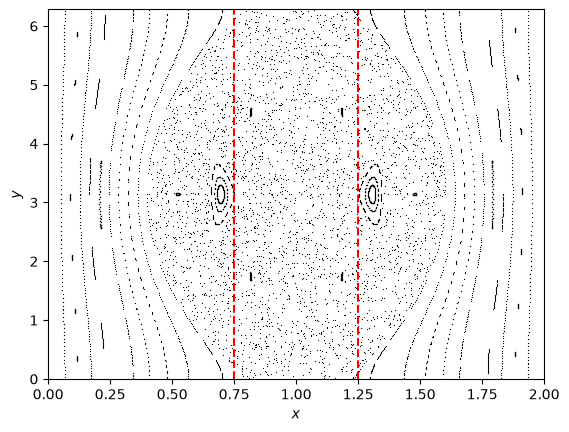

In [4]:
pplot = PoincarePlot.with_linspace(
    map,
    np.array([0.05, np.pi]),
    np.array([1.95, np.pi]),
    npts=50
)

# Follow each initial condition for 200 crossings
pplot.compute(npts=150)

# Plot directly in (x,y) coordinates
fig, ax = pplot.plot(plottype=None) # plottypeNone to directly plot in the coordinates of the map

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

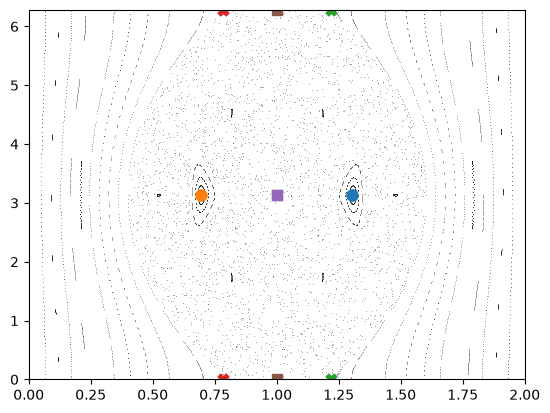

In [5]:
fig, ax = pplot.plot(
    s=0.5,
    xlim=[0, 2],
    ylim=[0, 2*np.pi],
    plottype=None
)


fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([xs1, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([xs2, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# Hyperbolic fixed points / X-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([1.2, 0.0]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([0.78, 2*np.pi]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# FP in the chaotic region:
result = fp.find(
    t = 1,
    guess = np.array([1., np.pi]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find(
    t = 1,
    guess = np.array([1., 6.]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

#### Find manifolds

In [31]:
fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.22, 0.0]), method="scipy.root")   

fp2 = FixedPoint(map)
fp2.find_with_iota(n = field.n1, m = field.m1, guess = np.array(fp1.coords[1]), method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.78, 0.2]), method="scipy.root")  

fp4 = FixedPoint(map)
fp4.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.78, 2*np.pi]), method="scipy.root")  

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 3]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")

In [ ]:
manifold1 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0]
)
manifold1.vector_s = np.real_if_close(manifold1.vector_s)
manifold1.vector_u = np.real_if_close(manifold1.vector_u)

manifold2 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0],
    first_stable=False
)
manifold2.vector_s = np.real_if_close(manifold2.vector_s)
manifold2.vector_u = np.real_if_close(manifold2.vector_u)

manifold3 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0]
)
manifold3.vector_s = np.real_if_close(manifold3.vector_s)
manifold3.vector_u = np.real_if_close(manifold3.vector_u)

manifold4 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0],
    first_stable=False
)
manifold4.vector_s = np.real_if_close(manifold4.vector_s)
manifold4.vector_u = np.real_if_close(manifold4.vector_u)

In [68]:
# manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.5e-3)
# manifold1.compute_adaptive(tol=5e-3, n_u_extra=-1, n_s_extra=-1)
    
manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.5e-3)
manifold2.compute_adaptive(tol=5e-3, n_u_extra=-2, n_s_extra=-1)

# manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
# manifold3.compute_adaptive()

# manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
# manifold4.compute_adaptive()

c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\scipy\integrate\_ode.py:356: ComplexWarning: Casting complex values to real discards the imaginary part
  self._y = asarray(y, self._integrator.scalar).copy()
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\slab_model\fields\slab_bfield_two_pert.py:56: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.array([Bx, By, Bz], dtype=np.float64)
Failed to refine clinic at eps_s=3.646638116322515e-09, eps_u=7.607965606551471e-11: Unstable epsilon guess is not in the linear regime, error is 0.0028704873546078202.
Failed to refine clinic at eps_s=7.02756760436316e-09, eps_u=8.003032222574215e-11: Unstable epsilon guess is not in the linear regime, error is 0.0024000088365490058.
Failed to refine clinic at eps_s=5.368698479727594e-07, eps_u=4.9248222591078204e-11: Unstable epsilon guess is not in the linear regime, error is 0.030751323809122044.
Failed to refine clinic at eps_s=5.363825548

(array([[1.21699928e+00+0.j, 6.56761602e-09+0.j],
        [1.21699928e+00+0.j, 8.80888081e-09+0.j],
        [1.21699928e+00+0.j, 1.40992387e-08+0.j],
        ...,
        [7.19384038e-01+0.j, 1.21561639e+00+0.j],
        [6.88401522e-01+0.j, 1.11442279e+00+0.j],
        [6.56253243e-01+0.j, 1.01051338e+00+0.j]], shape=(1082, 2)),
 array([[1.21699928+0.j, 6.2831853 +0.j],
        [1.21699928+0.j, 6.2831853 +0.j],
        [1.21699928+0.j, 6.28318529+0.j],
        ...,
        [0.75004691+0.j, 5.30530055+0.j],
        [0.7502039 +0.j, 5.30498128+0.j],
        [0.75036096+0.j, 5.30465825+0.j]], shape=(2030, 2)))

c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


(<Figure size 640x480 with 1 Axes>, <Axes: >)

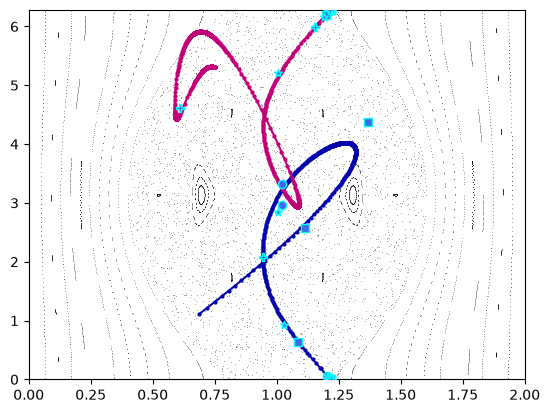

In [69]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

# manifold1.plot("both", ax=ax)
# manifold1.plot_clinics(ax=ax)
manifold2.plot("both", ax=ax)
manifold2.plot_clinics(ax=ax)
# manifold3.plot("both", ax=ax)
# manifold3.plot_clinics(ax=ax)
# manifold4.plot("both", ax=ax)
# manifold4.plot_clinics(ax=ax)
# ax.legend(loc="upper left")

(<Figure size 640x480 with 1 Axes>, <Axes: >)

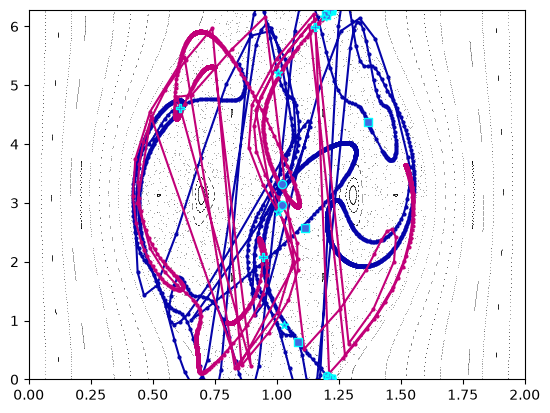

In [66]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

# manifold1.plot("both", ax=ax)
# manifold1.plot_clinics(ax=ax)
manifold2.plot("both", ax=ax)
manifold2.plot_clinics(ax=ax)
# manifold3.plot("both", ax=ax)
# manifold3.plot_clinics(ax=ax)
# manifold4.plot("both", ax=ax)
# manifold4.plot_clinics(ax=ax)
# ax.legend(loc="upper left")